# SE match posterior: linear model 2 chgpt

\Delta: 20, n: 100, Lmin: 3, Lmax: 3


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/703 [00:00<?, ?it/s]

Sum of row weights:  [656.73931602 666.32924601 676.93143796]


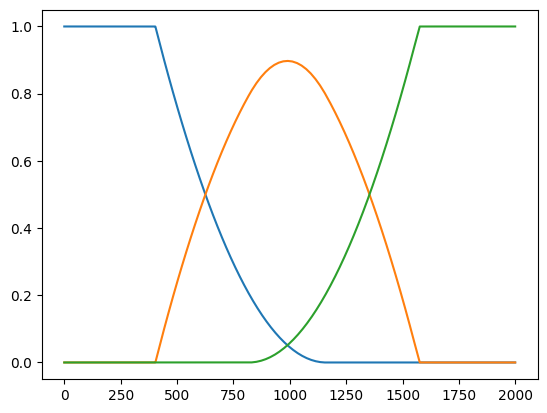

  0%|          | 0/17 [00:00<?, ?it/s]

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.general_fixed_point_eqns as fp
import WERM.marginals
import WERM.config
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)
import jax.random
import importlib
import WERM.estimators
importlib.reload(WERM.estimators)
importlib.reload(fp)
import WERM.posterior
importlib.reload(WERM.posterior)

# Set numpy random seed for reproducibility
random_seed = 42
np.random.seed(random_seed)
# Master PRNG key for reproducibility of all runs
MASTER_KEY = jax.random.PRNGKey(random_seed)

p = 1000 #8000
L = 3 # num signals. L-1 changepoints
noise_std = 2.0

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 20

# fractional_chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([1/3, 8/15])
# fractional_chgpt_locations = np.array([])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

δ = 2.0
n = int(δ * p)
if fractional_chgpt_locations.size != 0:
    true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
    C_true = η_to_ψ(true_chgpt_locations(n), n)
else:
    true_chgpt_locations = lambda n: np.array([])
    C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

# --- Preliminaries ---
# --- Compute weights as marginals of prior --- #
Δ = lambda n: int(n/5)
Delta_n = int(Δ(n))
L_is_upper_bound = False
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
print("Sum of row weights: ", π.sum(axis=1))
# # Normalize rows to sum to 1
# row_sums = π.sum(axis=1, keepdims=True)
# π = π / row_sums
# Plot pi
plt.plot(π.T)
plt.show()

    
### Extra

# Gaussian Signal Prior
κ = 1.0
B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
B̃_cov[0, 1] = 0.3 * κ**2 * δ  # Introduce some correlation between the first two signals
B̃_cov[1, 0] = 0.3 * κ**2 * δ  # Introduce some correlation between the first two signals
# B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
signal_prior = GaussianSignal(B̃_cov)

B̃ = signal_prior.sample(p)
ρ = 1/δ * 1/p * B̃.T @ B̃
key = jax.random.PRNGKey(0)

model_q = model.q_linear_model
ε = np.random.randn(n) * noise_std

# all_fp_solns = fp.compute_all_fixed_points(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=500)
# all_fp_solns = fp.compute_all_fixed_points_vmap(n, L, Δ(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY, coarse_grain_factor=4000, batch_size=32, max_iter=100, fp_lr=0.2, use_polyak_avg=True, early_stop_tol=1e-5)
all_fp_solns_naive = fp.compute_all_fixed_points_naive(n, L, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=20000, master_key=MASTER_KEY)
# b, nu, kappa, success_status = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY)
cp_arr = np.array([lis[0] for lis in all_fp_solns])
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint

post_samples = np.zeros((num_trials, len(cp_arr)))
theory_post_samples = np.zeros((num_trials, len(cp_arr)))

for trial_num in tqdm(range(num_trials)):
    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    # ε = jax.random.t(key, 5, shape=(n, ))
    # ε = np.random.standard_t(5, size=(n, ))
    # ε = np.random.uniform(0, 1, size=(n, ))

    Θ = X @ B̃
    # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    y_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0), out_axes=0)
    y = y_fn(Θ, C_true, ε)
    # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

    cp, gof, B̂ = WERM.estimators.weighted_erm(X, y, M, L, Δ(n), 0.0, L_is_upper_bound=L_is_upper_bound, brute_force=False, 
                                               return_gof=True, return_B_hat=True)
    

    Theta_hat = X @ B̂
    Theta_deb, b_hat = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ, output_b_hat=True)
    print("b_hat, b: ", b_hat, b)


    σ = noise_std
    posterior = WERM.posterior.exact_posterior_gaussian(cp_arr.astype(float), p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr)
    post_samples[trial_num, :] = posterior

    # Try theoretical posterior to see if matches
    # b, nu, kappa = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
    Z = np.random.multivariate_normal(np.zeros(L), ρ, size=n)
    G_Theta = np.random.multivariate_normal(np.zeros(L), kappa, size=n)
    V = Z @ nu + G_Theta
    y_bar = y_fn(Z, C_true, ε)
    theory_post = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, V, y_bar, ρ, σ, nu_arr, kappa_arr)
    theory_post_samples[trial_num, :] = theory_post

    # Sanity check: posterior should integrate to 1
    print("Theta cov: ", Theta_deb.T @ Theta_deb / n)
    print("V.T @ V / n: ", V.T @ V / n)
    print("nu.T @ ρ @ nu + kappa: ", nu.T @ ρ @ nu + kappa)


In [15]:
b_arr = np.array([lis[1] for lis in all_fp_solns])
all_fp_solns[50]

(array([1004, 1431], dtype=int32),
 Array([4.42819274, 4.26796272, 4.47439532], dtype=float64),
 Array([[4.38544202, 5.90324512, 8.26162715],
        [7.13773139, 6.42718439, 8.07050417],
        [6.35362416, 6.15143509, 1.94471083]], dtype=float64),
 Array([[1.47734373e+01, 1.66035047e+00, 7.30626521e-03],
        [1.66035047e+00, 1.10620076e+01, 1.78962994e+00],
        [7.30626521e-03, 1.78962994e+00, 1.50544482e+01]], dtype=float64),
 Array(False, dtype=bool))

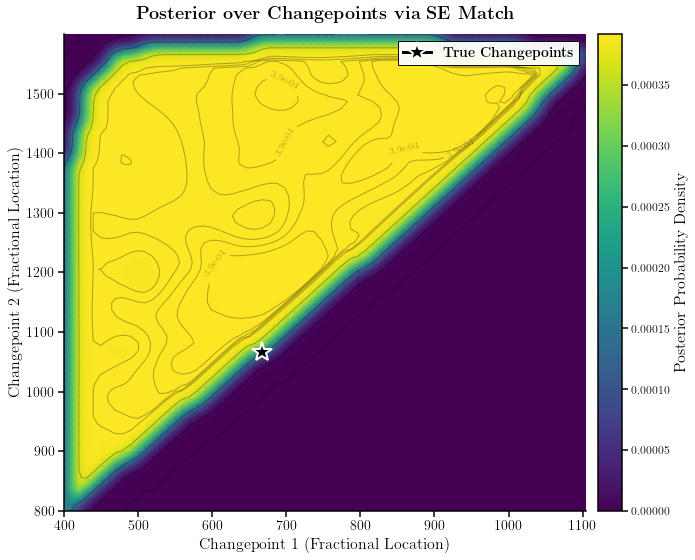

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

# Set up publication-ready plotting parameters
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Paul Tol "Vibrant" palette
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33']

def plot_2d_posterior_heatmap(cp_grid, probabilities, 
                             sigma=1.0, 
                             grid_resolution=200,
                             true_changepoints=None,
                             title=None,
                             xlabel=r'Changepoint 1 (Fractional Location)',
                             ylabel=r'Changepoint 2 (Fractional Location)',
                             cmap='YlOrRd',
                             figsize=(10, 8),
                             show_colorbar=True,
                             contour_levels=10,
                             add_contours=True):
    """
    Plot a smoothed 2D posterior distribution as a heatmap.
    
    Parameters:
    -----------
    cp_grid : array-like, shape (n_points, 2)
        Grid of changepoint locations
    probabilities : array-like, shape (n_points,)
        Probability values for each point in cp_grid
    sigma : float
        Standard deviation for Gaussian smoothing kernel
    grid_resolution : int
        Resolution of the interpolated grid
    true_changepoints : tuple or list of tuples, optional
        True changepoint locations to mark on the plot
    title : str, optional
        Plot title
    xlabel, ylabel : str
        Axis labels
    cmap : str or matplotlib colormap
        Colormap for the heatmap
    figsize : tuple
        Figure size
    show_colorbar : bool
        Whether to show colorbar
    contour_levels : int
        Number of contour levels
    add_contours : bool
        Whether to add contour lines
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    
    # Create figure with proper styling
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('white')
    
    # Extract x and y coordinates
    x = cp_grid[:, 0]
    y = cp_grid[:, 1]
    
    # Create a regular grid for interpolation
    xi = np.linspace(x.min(), x.max(), grid_resolution)
    yi = np.linspace(y.min(), y.max(), grid_resolution)
    Xi, Yi = np.meshgrid(xi, yi)
    
    # Interpolate the probabilities onto regular grid
    Zi = griddata((x, y), probabilities, (Xi, Yi), method='cubic', fill_value=0)
    
    # Apply Gaussian smoothing for KDE-like effect
    Zi_smooth = gaussian_filter(Zi, sigma=sigma)
    
    # Normalize to ensure it's a proper probability distribution
    Zi_smooth = Zi_smooth / np.sum(Zi_smooth)
    
    # Create the heatmap
    im = ax.pcolormesh(Xi, Yi, Zi_smooth, cmap=cmap, shading='gouraud')
    
    # Add contour lines if requested
    if add_contours:
        # Calculate contour levels based on probability quantiles
        prob_flat = Zi_smooth.flatten()
        prob_flat_sorted = np.sort(prob_flat[prob_flat > 0])
        if len(prob_flat_sorted) > contour_levels:
            level_indices = np.linspace(0, len(prob_flat_sorted)-1, contour_levels, dtype=int)
            levels = prob_flat_sorted[level_indices]
        else:
            levels = contour_levels
        
        contours = ax.contour(Xi, Yi, Zi_smooth, levels=levels, 
                             colors='black', alpha=0.3, linewidths=1.0)
        
        # Add contour labels for highest probability regions
        if len(contours.levels) > 3:
            ax.clabel(contours, contours.levels[-3:], inline=True, fontsize=10, fmt='%.1e')
    
    # Mark true changepoints if provided
    if true_changepoints is not None:
        if isinstance(true_changepoints, tuple) and len(true_changepoints) == 2:
            # Single pair of changepoints
            ax.plot(true_changepoints[0], true_changepoints[1], 
                   marker='*', markersize=20, color='black', 
                   markeredgecolor='white', markeredgewidth=2,
                   label=r'\textbf{True Changepoints}', zorder=100)
        else:
            # Multiple pairs
            for i, (cp1, cp2) in enumerate(true_changepoints):
                ax.plot(cp1, cp2, marker='*', markersize=20, color='black',
                       markeredgecolor='white', markeredgewidth=2,
                       label=r'\textbf{True Changepoints}' if i == 0 else "",
                       zorder=100)
    
    # Add colorbar if requested
    if show_colorbar:
        cbar = fig.colorbar(im, ax=ax, pad=0.02)
        cbar.set_label(r'Posterior Probability Density', fontsize=16)
        cbar.ax.tick_params(labelsize=12, width=1.5, length=6)
        cbar.outline.set_linewidth(1.5)
    
    # Set labels and title
    ax.set_xlabel(xlabel, fontsize=16)
    ax.set_ylabel(ylabel, fontsize=16)
    
    if title:
        ax.set_title(title, fontsize=18, pad=15)
    
    # Style the axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    
    # Add legend if true changepoints were marked
    if true_changepoints is not None:
        ax.legend(loc='upper right', fontsize=14, frameon=True,
                 edgecolor='black', framealpha=0.95)
    
    # Set axis limits to data range
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(y.min(), y.max())
    
    plt.tight_layout()
    
    return fig, ax

                                    # probabilities=theory_post_samples.mean(axis=0),
fig, ax = plot_2d_posterior_heatmap(cp_grid=cp_arr, 
                                    probabilities=b_arr[:, 0],
                                    sigma=1.0,
                                    grid_resolution=72,
                                    true_changepoints=(fractional_chgpt_locations[0]*n, fractional_chgpt_locations[1]*n) if len(fractional_chgpt_locations) >= 2 else None,
                                    title=r'\textbf{Posterior over Changepoints via SE Match}',
                                    add_contours=True,
                                    show_colorbar=True,
                                    cmap='viridis',
                                    )

plt.show()


In [12]:
b_arr

[Array([4.40920076, 4.35013416, 4.50669279], dtype=float64),
 Array([4.40793708, 4.33628051, 4.51203981], dtype=float64),
 Array([4.41828208, 4.32810444, 4.50686252], dtype=float64),
 Array([4.41408031, 4.33136201, 4.50421998], dtype=float64),
 Array([4.42087026, 4.31298907, 4.50395041], dtype=float64),
 Array([4.41946407, 4.31910289, 4.50652088], dtype=float64),
 Array([4.42384841, 4.30698204, 4.50839124], dtype=float64),
 Array([4.40740482, 4.30618868, 4.50664022], dtype=float64),
 Array([4.42217649, 4.3059679 , 4.51035739], dtype=float64),
 Array([4.42602743, 4.29631928, 4.50873669], dtype=float64),
 Array([4.40655759, 4.30576073, 4.51272789], dtype=float64),
 Array([4.4161123 , 4.30188747, 4.50584227], dtype=float64),
 Array([4.41854619, 4.29047847, 4.51395857], dtype=float64),
 Array([4.42487876, 4.3019851 , 4.50824921], dtype=float64),
 Array([4.41533733, 4.29170981, 4.50660832], dtype=float64),
 Array([4.42972081, 4.29477936, 4.49626841], dtype=float64),
 Array([4.41675087, 4.29

True changepoint: 666
Closest changepoint to 666 is [ 710 1444] at index 52
Closest nu at index 52: [[4.58867748 6.47098721 8.22011438]
 [6.92386482 5.54660754 8.00196061]
 [6.40353459 6.31477656 2.15469471]]
Closest kappa at index 52: [[1.43440228e+01 1.88260176e+00 8.33054362e-03]
 [1.88260176e+00 1.12846087e+01 1.78119489e+00]
 [8.33054362e-03 1.78119489e+00 1.60999230e+01]]
Actual nu: [[ 0.81358877  0.21237082  0.03709544]
 [ 0.20232564  0.44606465 -0.02139132]
 [ 0.09531702  0.47851439  1.02413997]]
Actual kappa: [[1.99122109 0.31018982 0.00221183]
 [0.31018982 1.60029999 0.28838973]
 [0.00221183 0.28838973 1.46411011]]
Closest index to actual nu and kappa: 68
Closest nu at index 68: [[5.07156727 6.71591122 8.11620186]
 [6.38918481 4.87210582 7.68779354]
 [6.52033708 6.48099396 2.61567023]]
Closest kappa at index 68: [[1.33563422e+01 1.64992145e+00 7.42637511e-03]
 [1.64992145e+00 1.05846315e+01 1.64061031e+00]
 [7.42637511e-03 1.64061031e+00 1.49223734e+01]]
Actual nu: [[ 0.81358

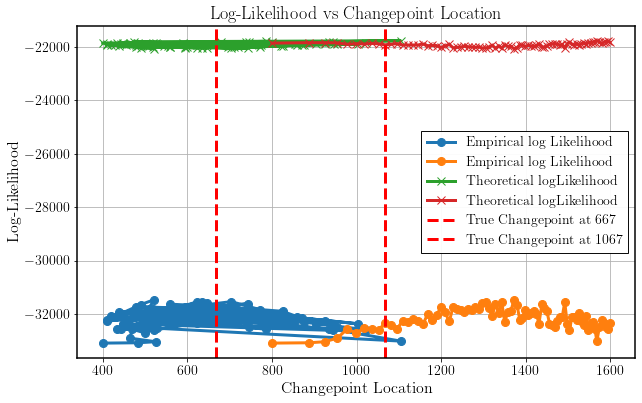

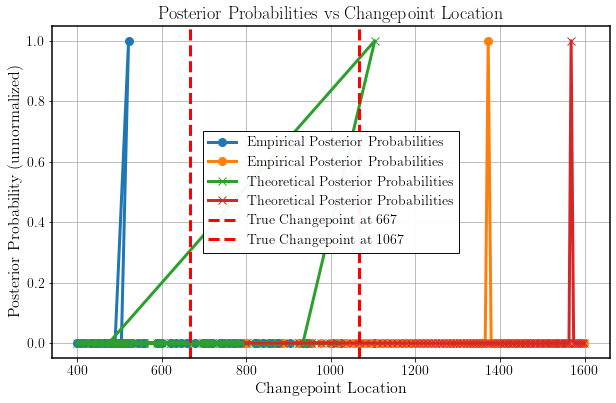

In [5]:
# Find the change point in cp_arr closest to the true changepoint
if true_chgpt_locations(n).size > 0:
    true_cp = true_chgpt_locations(n)[0]
    print(f"True changepoint: {true_cp}")
    closest_cp_index = np.argmin(np.abs(cp_arr - true_cp))
    closest_cp_value = cp_arr[closest_cp_index]
    print(f"Closest changepoint to {true_cp} is {closest_cp_value} at index {closest_cp_index}")

# Compare nu_arr[closest_cp_index] with nu, and kappa_arr[closest_cp_index] with kappa
closest_nu = nu_arr[closest_cp_index]
closest_kappa = kappa_arr[closest_cp_index]
print(f"Closest nu at index {closest_cp_index}: {closest_nu}")
print(f"Closest kappa at index {closest_cp_index}: {closest_kappa}")
print(f"Actual nu: {nu}")
print(f"Actual kappa: {kappa}")

# Find the closest nu and kappa to the actual nu and kappa
nu_diff = np.linalg.norm(nu_arr - nu, axis=(1, 2))
kappa_diff = np.linalg.norm(kappa_arr - kappa, axis=(1, 2))
total_diff = nu_diff + kappa_diff
closest_index = np.argmin(total_diff)
print(f"Closest index to actual nu and kappa: {closest_index}")
print(f"Closest nu at index {closest_index}: {nu_arr[closest_index]}")
print(f"Closest kappa at index {closest_index}: {kappa_arr[closest_index]}")
print(f"Actual nu: {nu}")
print(f"Actual kappa: {kappa}")

log_lik = WERM.posterior.logP_V_Y_given_η_jax_allη(cp_arr, Theta_deb, y, ρ, noise_std, nu_arr, kappa_arr)
log_lik_theory = WERM.posterior.logP_V_Y_given_η_jax_allη(cp_arr, V, y_bar, ρ, noise_std, nu_arr, kappa_arr)
# Plot log likelihoods
plt.figure(figsize=(10, 6))
plt.plot(cp_arr, log_lik, label='Empirical log Likelihood', marker='o')
plt.plot(cp_arr, log_lik_theory, label='Theoretical logLikelihood', marker='x')
for frac_cp in fractional_chgpt_locations:
    plt.axvline(x=frac_cp * n, color='red', linestyle='--', label=f'True Changepoint at {frac_cp * n:.0f}')
plt.xlabel('Changepoint Location')
plt.ylabel('Log-Likelihood')
plt.title('Log-Likelihood vs Changepoint Location')
plt.legend()
plt.grid(True)
plt.show()

# Plot the probabilities np.exp(log_lik - np.max(log_lik)) to avoid overflow
plt.figure(figsize=(10, 6))
plt.plot(cp_arr, np.exp(log_lik - np.max(log_lik)), label='Empirical Posterior Probabilities', marker='o')
plt.plot(cp_arr, np.exp(log_lik_theory - np.max(log_lik_theory)), label='Theoretical Posterior Probabilities', marker='x')
for frac_cp in fractional_chgpt_locations:
    plt.axvline(x=frac_cp * n, color='red', linestyle='--', label=f'True Changepoint at {frac_cp * n:.0f}')
plt.xlabel('Changepoint Location')
plt.ylabel('Posterior Probability (unnormalized)')
plt.title('Posterior Probabilities vs Changepoint Location')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
np.exp(log_lik - np.max(log_lik))

array([1.00000000e+000, 2.75276528e-308, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 1.37019386e-226])

In [47]:
b, nu, kappa = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)

Optimization Results: all =       message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [-4.998e-04 -4.615e-04 -2.973e-08  1.329e-07 -2.716e-07
                2.511e-07  6.503e-05  6.543e-05  6.543e-05  6.464e-05]
           x: [ 7.421e+09  6.955e+09  1.017e+00  1.014e+00  1.599e-02
                2.219e-02  8.765e+00  8.827e+00  3.295e-01]
        cost: 2.39864012480686e-07
         jac: [[ 6.666e-14  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  6.563e-14 ...  0.000e+00  0.000e+00]
               ...
               [-5.030e-12 -4.909e-12 ...  1.180e-01 -1.321e-02]
               [ 0.000e+00 -9.824e-12 ...  2.363e-01 -2.252e-02]]
        grad: [-1.335e-15 -1.308e-15  1.519e-07 -2.475e-07  2.217e-07
               -2.779e-07  3.089e-05  3.071e-05 -3.182e-06]
  optimality: 0.000270729201063819
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 200
        njev: 170 success =  False , message =  The maximum nu

In [50]:
print(f"Fixed point solution: b={b}, nu={nu}, kappa={kappa}")

Fixed point solution: b=[7.42129525e+09 6.95463648e+09], nu=[[1.01681738 1.01369304]
 [0.01598834 0.02218553]], kappa=[[76.83070854 77.37058405]
 [77.37058405 78.02280786]]


In [49]:
import importlib
import WERM.posterior
importlib.reload(WERM.posterior)
import WERM.general_fixed_point_eqns as fp
importlib.reload(fp)

b, nu, kappa = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model)

Theta_hat = X @ B̂
Theta_deb = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ)

cp_arr = np.array([lis[0] for lis in all_fp_solns])
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
print(cp_arr.shape)
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint

σ = noise_std
posterior = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr)

# Try theoretical posterior to see if matches
b, nu, kappa = fp.general_fp(M, ρ, δ, true_chgpt_locations(n), π, ε, n, model.q_linear_model)
Z = np.random.multivariate_normal(np.zeros(L), ρ, size=n)
G_Theta = np.random.multivariate_normal(np.zeros(L), kappa, size=n)
V = Z @ nu + G_Theta
y_bar = y_fn(Z, C_true, ε)
theory_post = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, V, y_bar, ρ, σ, nu_arr, kappa_arr)

Optimization Results: all =       message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [-8.374e-04 -7.681e-04  3.550e-08 -1.467e-07 -4.449e-07
                4.387e-07  9.123e-05  9.246e-05  9.246e-05  9.116e-05]
           x: [ 4.399e+09  4.148e+09  3.214e-01  3.149e-01  7.206e-01
                7.325e-01  9.842e+00  9.922e+00  5.893e-01]
        cost: 6.62417238387559e-07
         jac: [[ 1.871e-13  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  1.818e-13 ...  0.000e+00  0.000e+00]
               ...
               [-1.784e-11 -1.737e-11 ...  1.337e-01 -8.843e-03]
               [ 0.000e+00 -3.470e-11 ...  2.673e-01 -9.862e-03]]
        grad: [-6.634e-15 -6.515e-15  1.998e-07 -1.366e-07  1.939e-07
               -1.545e-07  4.935e-05  4.910e-05 -2.528e-06]
  optimality: 0.00048574143865596326
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 200
        njev: 170 success =  False , message =  The maximum 

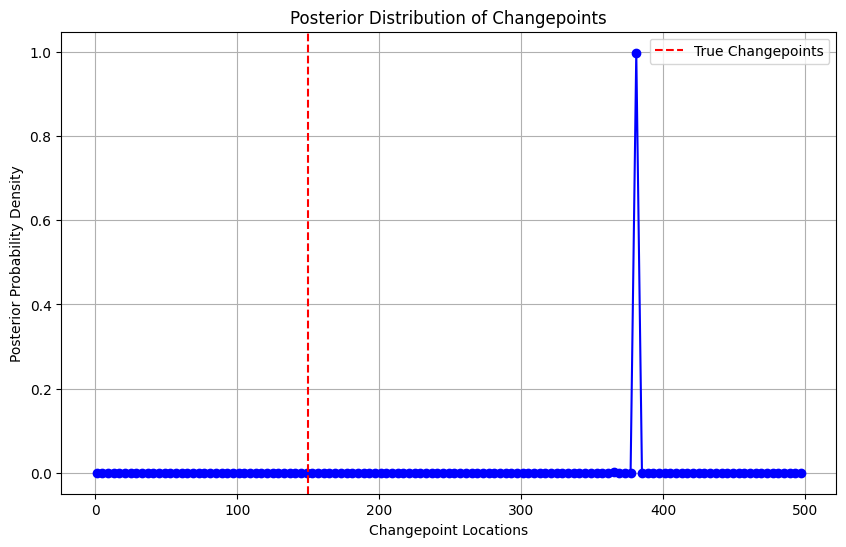

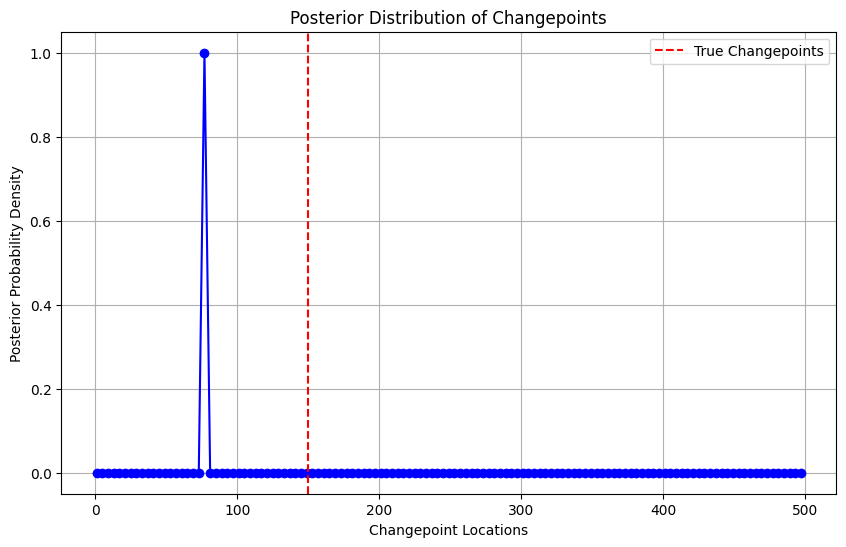

In [12]:
# Plot the posterior

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(cp_arr, posterior, marker='o', linestyle='-', color='b')
# Plot a dashed vertical line at fractional changepoint locations * n
plt.axvline(x=true_chgpt_locations(n), color='r', linestyle='--', label='True Changepoints')
plt.legend()
plt.title('Posterior Distribution of Changepoints')
plt.xlabel('Changepoint Locations')
plt.ylabel('Posterior Probability Density')
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(cp_arr, theory_post, marker='o', linestyle='-', color='b')
# Plot a dashed vertical line at fractional changepoint locations * n
plt.axvline(x=true_chgpt_locations(n), color='r', linestyle='--', label='True Changepoints')
plt.legend()
plt.title('Posterior Distribution of Changepoints')
plt.xlabel('Changepoint Locations')
plt.ylabel('Posterior Probability Density')
plt.grid()
plt.show()

# Extrapolation code

In [60]:
import WERM.posterior
importlib.reload(WERM.posterior)

n_small = 100
Delta_n_small = Δ(n_small)
if L_is_upper_bound: 
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    Lmin = 1
    Lmax = L
else:
    p_l = None
    Lmin = L
    Lmax = L
pi_small = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n_small, p_l = p_l, verbose = False)
ε_small = ε[:n_small]
print("Shapes: ", pi_small.shape, ε_small.shape, Δ(n_small), n_small, L, Delta_n_small)

small_indices = np.linspace(0, n-1, n_small, dtype=int)
X_small = X[small_indices]
pred_soln, grid_fractional = WERM.posterior.fixed_pt_sol_extrapolate(
    n_large=n, n_small=n_small, L=L, Delta_fn = Δ, M_func=M, ρ=ρ, δ=δ, π_small=pi_small, ε_small=ε_small, 
    q_func=model.q_linear_model, master_key=MASTER_KEY, coarse_grain_factor=1, est_b=True, X_small=X[small_indices], y_small=y[small_indices]
)

\Delta: 10, n: 100, Lmin: 2, Lmax: 2


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Shapes:  (2, 100) (100,) 10 100 2 10
### Step 1 & 2: Generating Training Data... ###


  0%|          | 0/80 [00:00<?, ?it/s]

\Delta: 5, n: 50, Lmin: 2, Lmax: 2


... (237 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  Tested 99 valid positions
  Best 5 improvements: [(48, Array(27.12679942, dtype=float64), Array(3.93865645e-06, dtype=float64)), (47, Array(27.12679941, dtype=float64), Array(3.94740771e-06, dtype=float64)), (46, Array(27.1267994, dtype=float64), Array(3.95532828e-06, dtype=float64)), (49, Array(27.12679938, dtype=float64), Array(3.97406963e-06, dtype=float64)), (50, Array(27.12679938, dtype=float64), Array(3.98004744e-06, dtype=float64))]

Applying local refinement...
Using estimated b_hat = [1073.47345544 1022.57639333] to constrain b in [[1019.79978267  971.44757367], [1127.14712821 1073.705213  ]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.196e-01 -1.098e-01  4.324e-15 -5.110e-16  2.693e-15
                1.441e-15 -1.544e-14  1.475e-13  1.475e-13  5.541e-13]
           x: [ 1.127e+03  1.074e+03  8.954e-01  7.972e-01  9.903e-02
                2.437e-01  2.226e+00  1.216e+00  2.328e+0

ValueError: not enough values to unpack (expected 5, got 4)

In [35]:
pred_soln[0]
print(grid_fractional)

[[0.1  ]
 [0.101]
 [0.102]
 [0.103]
 [0.104]
 [0.105]
 [0.106]
 [0.107]
 [0.108]
 [0.109]
 [0.11 ]
 [0.111]
 [0.112]
 [0.113]
 [0.114]
 [0.115]
 [0.116]
 [0.117]
 [0.118]
 [0.119]
 [0.12 ]
 [0.121]
 [0.122]
 [0.123]
 [0.124]
 [0.125]
 [0.126]
 [0.127]
 [0.128]
 [0.129]
 [0.13 ]
 [0.131]
 [0.132]
 [0.133]
 [0.134]
 [0.135]
 [0.136]
 [0.137]
 [0.138]
 [0.139]
 [0.14 ]
 [0.141]
 [0.142]
 [0.143]
 [0.144]
 [0.145]
 [0.146]
 [0.147]
 [0.148]
 [0.149]
 [0.15 ]
 [0.151]
 [0.152]
 [0.153]
 [0.154]
 [0.155]
 [0.156]
 [0.157]
 [0.158]
 [0.159]
 [0.16 ]
 [0.161]
 [0.162]
 [0.163]
 [0.164]
 [0.165]
 [0.166]
 [0.167]
 [0.168]
 [0.169]
 [0.17 ]
 [0.171]
 [0.172]
 [0.173]
 [0.174]
 [0.175]
 [0.176]
 [0.177]
 [0.178]
 [0.179]
 [0.18 ]
 [0.181]
 [0.182]
 [0.183]
 [0.184]
 [0.185]
 [0.186]
 [0.187]
 [0.188]
 [0.189]
 [0.19 ]
 [0.191]
 [0.192]
 [0.193]
 [0.194]
 [0.195]
 [0.196]
 [0.197]
 [0.198]
 [0.199]
 [0.2  ]
 [0.201]
 [0.202]
 [0.203]
 [0.204]
 [0.205]
 [0.206]
 [0.207]
 [0.208]
 [0.209]
 [0.21 ]
 

In [34]:
# Find the index of the closest changepoint in pred_soln to the true changepoint
if true_chgpt_locations(n).size > 0:
    true_cp = true_chgpt_locations(n)[0]
    print(f"True changepoint: {true_cp}")
    closest_cp_index = np.argmin(np.abs(pred_soln[0] - true_cp))
    closest_cp_value = pred_soln[0][closest_cp_index]
    print(f"Closest changepoint to {true_cp} is {closest_cp_value} at index {closest_cp_index}")

True changepoint: 300


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (3, 2) + inhomogeneous part.

In [36]:
cp_arr = grid_fractional
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint
nu_arr = np.array([lis[1] for lis in pred_soln]).reshape((-1, L, L))
kappa_arr = np.array([lis[2] for lis in pred_soln]).reshape((-1, L, L))

In [47]:
all_fp_solns

[(array([100], dtype=int32),
  Array([3168450.12486324, 3422744.17348752], dtype=float64),
  Array([[0.08144661, 0.03293834],
         [0.94377408, 0.96550581]], dtype=float64),
  Array([[10.79492921,  7.05638889],
         [ 7.05638889, 13.95092793]], dtype=float64),
  True),
 (array([104], dtype=int32),
  Array([3638629.37209558, 3864774.96014886], dtype=float64),
  Array([[0.14062122, 0.11972112],
         [0.86433996, 0.90093221]], dtype=float64),
  Array([[11.18791037,  5.70862167],
         [ 5.70862167, 11.03255978]], dtype=float64),
  True),
 (array([108], dtype=int32),
  Array([2001167.62845033, 2176534.81003835], dtype=float64),
  Array([[0.13580624, 0.00700848],
         [0.85498208, 0.95836939]], dtype=float64),
  Array([[10.85018659,  5.4807372 ],
         [ 5.4807372 , 11.99448784]], dtype=float64),
  True),
 (array([112], dtype=int32),
  Array([2541303.81226474, 2673873.696006  ], dtype=float64),
  Array([[0.15152526, 0.06422499],
         [0.85434521, 0.95824268]], dtyp

In [57]:
import WERM.general_fixed_point_eqns
importlib.reload(WERM.general_fixed_point_eqns)

n_small = 50
print("Shapes: ", pi_small.shape, ε_small.shape, Δ(n_small), n_small, L)
naive_solns = WERM.general_fixed_point_eqns.compute_all_fixed_points_naive(n_small, L, Δ(n_small), M, ρ, δ, pi_small, ε_small, model.q_linear_model,
                                                                           est_b = True, X=X[:n_small], y=y[:n_small])

Shapes:  (2, 50) (50,) 5 50 2


  0%|          | 0/40 [00:00<?, ?it/s]

\Delta: 5, n: 50, Lmin: 2, Lmax: 2


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  Tested 49 valid positions
  Best 5 improvements: [(28, Array(4.25445825, dtype=float64), Array(1.14120258e-06, dtype=float64)), (24, Array(4.25445825, dtype=float64), Array(1.14419783e-06, dtype=float64)), (27, Array(4.25445825, dtype=float64), Array(1.14504043e-06, dtype=float64)), (23, Array(4.25445825, dtype=float64), Array(1.14534692e-06, dtype=float64)), (26, Array(4.25445824, dtype=float64), Array(1.14865823e-06, dtype=float64))]

Applying local refinement...
Using estimated b_hat = [1175.56247091 1064.4821946 ] to constrain b in [[1116.78434736 1011.25808487], [1234.34059446 1117.70630433]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.386e-01 -1.190e-01  4.506e-13  1.866e-13 -2.567e-13
               -1.762e-13  8.231e-11  8.454e-12  8.454e-12  1.224e-11]
           x: [ 1.234e+03  1.118e+03  7.965e-02 -2.622e-01  9.382e-01
                1.215e+00  2.972e+00  8.907e-01  1.879e+00]
 

... (113 outputs left out)

  Tested 49 valid positions
  Best 5 improvements: [(28, Array(4.25445825, dtype=float64), Array(1.14120258e-06, dtype=float64)), (24, Array(4.25445825, dtype=float64), Array(1.14419783e-06, dtype=float64)), (27, Array(4.25445825, dtype=float64), Array(1.14504043e-06, dtype=float64)), (23, Array(4.25445825, dtype=float64), Array(1.14534692e-06, dtype=float64)), (26, Array(4.25445824, dtype=float64), Array(1.14865823e-06, dtype=float64))]

Applying local refinement...
Using estimated b_hat = [1175.56247091 1064.4821946 ] to constrain b in [[1116.78434736 1011.25808487], [1234.34059446 1117.70630433]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.386e-01 -1.190e-01  2.736e-11  1.597e-14 -2.306e-11
               -5.184e-15  3.550e-09  8.331e-10  8.331e-10  3.066e-12]
           x: [ 1.234e+03  1.118e+03  9.509e-01  5.764e-01  5.554e-02
                3.722e-01  2.868e+00  9.143e-01  1.929e+00]
 

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/38 [00:00<?, ?it/s]

  Tested 49 valid positions
  Best 5 improvements: [(28, Array(4.25445825, dtype=float64), Array(1.14120258e-06, dtype=float64)), (24, Array(4.25445825, dtype=float64), Array(1.14419783e-06, dtype=float64)), (27, Array(4.25445825, dtype=float64), Array(1.14504043e-06, dtype=float64)), (23, Array(4.25445825, dtype=float64), Array(1.14534692e-06, dtype=float64)), (26, Array(4.25445824, dtype=float64), Array(1.14865823e-06, dtype=float64))]

Applying local refinement...
Using estimated b_hat = [1175.56247091 1064.4821946 ] to constrain b in [[1116.78434736 1011.25808487], [1234.34059446 1117.70630433]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.386e-01 -1.190e-01  1.770e-11  9.336e-15 -1.148e-11
               -7.381e-15  2.636e-09  6.148e-10  6.148e-10  2.265e-12]
           x: [ 1.234e+03  1.118e+03  9.531e-01  5.919e-01  5.325e-02
                3.560e-01  2.867e+00  9.140e-01  1.943e+00]
 